In [77]:
import pandas as pd

sba_old = pd.read_csv(
    "data/raw/FOIA_7a_FY2010_FY2019_asof_260930.csv",
    low_memory=False
)
sba_new = pd.read_csv(
    "data/raw/FOIA_7a_FY2020_Present_asof_260930.csv",
    low_memory=False
)

In [78]:

# Dataset dimensions
print("Old SBA shape:", sba_old.shape)
print("New SBA shape:", sba_new.shape)

# Preview records
print(sba_old.head())
print(sba_new.head())

# Loan status counts
print(sba_old["LoanStatus"].value_counts())
print(sba_new["LoanStatus"].value_counts())

# Missing values
print(sba_old.isna().sum())
print(sba_new.isna().sum())

# Duplicate counts
print("Old SBA duplicates:", sba_old.duplicated().sum())
print("New SBA duplicates:", sba_new.duplicated().sum())

Old SBA shape: (545751, 42)
New SBA shape: (403644, 42)
     AsOfDate Program  LocationID  \
0  2026-09-30      7A     12096.0   
1  2026-09-30      7A     89255.0   
2  2026-09-30      7A     29760.0   
3  2026-09-30      7A     44449.0   
4  2026-09-30      7A    507814.0   

                                            BorrName  \
0           United Renal Associates of Georgia, P.C.   
1                                   Sylvia H. Caruso   
2                               Bangor Wine & Cheese   
3  Brainy Bunch Learning Center dba Kiddie Academ...   
4           ON SITE AUTOMOTIVE APPEARANCE SPECIALIST   

                                   BorrStreet      BorrCity BorrState  \
0  5669 Peachtree Dunwoody Road NE, Suite 240       Atlanta        GA   
1                       5 BROADWAY, SUITE 104        SAUGUS        MA   
2                           436 State Street.        Bangor        ME   
3                            301 Wartman Road  COLLEGEVILLE        PA   
4                  

In [79]:
# Combine old and new SBA datasets
sba_combined = pd.concat(
    [sba_old, sba_new],
    ignore_index=True
)

# Check combined dataset dimensions
print("Combined SBA dataset shape:", sba_combined.shape)

# Display loan status counts
print("\nCombined loan status counts:")
print(sba_combined["LoanStatus"].value_counts())

# Check duplicate records
print("\nDuplicate rows:", sba_combined.duplicated().sum())

# Preview combined dataset
print("\nFirst five records:")
print(sba_combined.head())

# Check missing values
print("\nMissing values by column:")
print(sba_combined.isna().sum())

Combined SBA dataset shape: (949395, 42)

Combined loan status counts:
LoanStatus
P I F     472321
EXEMPT    293110
CANCLD    119685
CHGOFF     42756
COMMIT     21523
Name: count, dtype: int64

Duplicate rows: 1532

First five records:
     AsOfDate Program  LocationID  \
0  2026-09-30      7A     12096.0   
1  2026-09-30      7A     89255.0   
2  2026-09-30      7A     29760.0   
3  2026-09-30      7A     44449.0   
4  2026-09-30      7A    507814.0   

                                            BorrName  \
0           United Renal Associates of Georgia, P.C.   
1                                   Sylvia H. Caruso   
2                               Bangor Wine & Cheese   
3  Brainy Bunch Learning Center dba Kiddie Academ...   
4           ON SITE AUTOMOTIVE APPEARANCE SPECIALIST   

                                   BorrStreet      BorrCity BorrState  \
0  5669 Peachtree Dunwoody Road NE, Suite 240       Atlanta        GA   
1                       5 BROADWAY, SUITE 104        SAUGU

In [81]:
# CHUNK 3: SBA DATA CLEANING AND DEFAULT TARGET

# 1. Create a copy of the combined dataset
sba_clean = sba_combined.copy()

# 2. Remove exact duplicate rows
print("Rows before cleaning:", len(sba_clean))

sba_clean = sba_clean.drop_duplicates().reset_index(drop=True)

print("Rows after cleaning:", len(sba_clean))
print("Duplicates remaining:", sba_clean.duplicated().sum())

# 3. Check loan status distribution
print("\nLoan statuses after cleaning:")
print(sba_clean["LoanStatus"].value_counts())

# 4. Select loans with resolved repayment outcomes
# P I F = Paid in Full
# CHGOFF = Charged Off

sba_model = sba_clean[
    sba_clean["LoanStatus"].isin(["P I F", "CHGOFF"])
].copy()

# 5. Create the prediction target
# 1 = Default (Charged Off)
# 0 = Non-default (Paid in Full)

sba_model["Default"] = (
        sba_model["LoanStatus"] == "CHGOFF"
).astype(int)

# 6. Check target distribution
print("\nDefault target distribution:")
print(sba_model["Default"].value_counts())

print("\nDefault percentages:")
print(sba_model["Default"].value_counts(normalize=True) * 100)

# 7. Verify the cleaned modeling dataset
print("\nModeling dataset shape:", sba_model.shape)
print("Missing target values:", sba_model["Default"].isna().sum())

# 8. Preview results
print(
    sba_model[
        ["LoanStatus", "Default", "GrossApproval", "ApprovalFY"]
    ].head()
)

Rows before cleaning: 949395
Rows after cleaning: 947863
Duplicates remaining: 0

Loan statuses after cleaning:
LoanStatus
P I F     471986
EXEMPT    293025
CANCLD    118579
CHGOFF     42756
COMMIT     21517
Name: count, dtype: int64

Default target distribution:
Default
0    471986
1     42756
Name: count, dtype: int64

Default percentages:
Default
0    91.693703
1     8.306297
Name: proportion, dtype: float64

Modeling dataset shape: (514742, 43)
Missing target values: 0
  LoanStatus  Default  GrossApproval  ApprovalFY
0      P I F        0        51000.0        2010
1      P I F        0        30000.0        2010
2      P I F        0        74000.0        2010
3      P I F        0       647000.0        2010
4      P I F        0        12500.0        2010


In [83]:
# CHUNK 4: FEATURE SELECTION AND MISSING-VALUE ANALYSIS

# 1. Select potential prediction features
features = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "InitialInterestRate",
    "TermInMonths",
    "NaicsCode",
    "BusinessType",
    "BusinessAge",
    "ProjectState",
    "ProjectCounty",
    "CollateralInd",
    "ProcessingMethod",
    "ApprovalFY"
]

# 2. Check that all selected columns exist
missing_columns = [
    col for col in features if col not in sba_model.columns
]

print("Missing feature columns:", missing_columns)

if missing_columns:
    raise ValueError(
        f"These columns are missing: {missing_columns}"
    )

# 3. Create feature matrix and target
X = sba_model[features].copy()
y = sba_model["Default"].copy()

# 4. Check dimensions
print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

# 5. Inspect feature data types
print("\nFeature data types:")
print(X.dtypes)

# 6. Count missing values
print("\nMissing values by feature:")
print(X.isna().sum().sort_values(ascending=False))

# 7. Calculate missing percentages
print("\nMissing percentages:")
missing_percent = X.isna().mean() * 100
print(missing_percent.sort_values(ascending=False).round(2))

# 8. Separate numerical and categorical features
numerical_features = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "InitialInterestRate",
    "TermInMonths"
]

categorical_features = [
    "NaicsCode",
    "BusinessType",
    "BusinessAge",
    "ProjectState",
    "ProjectCounty",
    "CollateralInd",
    "ProcessingMethod",
    "ApprovalFY"
]

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# 9. Check class distribution
print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

# 10. Preview selected features
print("\nSelected feature preview:")
print(X.head())

Missing feature columns: []

Feature matrix shape: (514742, 12)
Target shape: (514742,)

Feature data types:
GrossApproval            float64
SBAGuaranteedApproval    float64
InitialInterestRate      float64
TermInMonths             float64
NaicsCode                float64
BusinessType                 str
BusinessAge                  str
ProjectState                 str
ProjectCounty                str
CollateralInd                str
ProcessingMethod             str
ApprovalFY                 int64
dtype: object

Missing values by feature:
BusinessAge              1395
BusinessType               29
NaicsCode                   2
InitialInterestRate         1
TermInMonths                0
SBAGuaranteedApproval       0
GrossApproval               0
ProjectState                0
ProjectCounty               0
CollateralInd               0
ProcessingMethod            0
ApprovalFY                  0
dtype: int64

Missing percentages:
BusinessAge              0.27
BusinessType             0.0

In [84]:
# Inspect available years
sba_model["ApprovalFY"].value_counts().sort_index()

# Example chronological condition
sba_model["ApprovalFY"] <= 2018

0          True
1          True
2          True
3          True
4          True
          ...  
927045    False
928507    False
930947    False
932203    False
939332    False
Name: ApprovalFY, Length: 514742, dtype: bool

In [85]:
# Define training and testing conditions
train_mask = sba_model["ApprovalFY"] <= 2018
test_mask = sba_model["ApprovalFY"] > 2018

# Create training and testing datasets
train_data = sba_model[train_mask].copy()
test_data = sba_model[test_mask].copy()

# Separate features
X_train = train_data[features].copy()
X_test = test_data[features].copy()

# Separate target
y_train = train_data["Default"].copy()
y_test = test_data["Default"].copy()

In [86]:
# CHUNK 5: CHRONOLOGICAL TRAIN/TEST SPLIT

#  Check approval years
print("Loans by approval year:")
print(sba_model["ApprovalFY"].value_counts().sort_index())

#  Define training and testing conditions
train_mask = sba_model["ApprovalFY"] <= 2018
test_mask = sba_model["ApprovalFY"] > 2018

#  Verify the split
print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining default percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting default percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# 7. Verify chronological separation
print("\nLatest training year:", train_data["ApprovalFY"].max())
print("Earliest testing year:", test_data["ApprovalFY"].min())

Loans by approval year:
ApprovalFY
2010    39305
2011    44636
2012    37786
2013    38812
2014    43941
2015    52299
2016    52215
2017    47643
2018    42901
2019    32444
2020    23557
2021    22850
2022    14046
2023    11560
2024     7449
2025     3061
2026      237
Name: count, dtype: int64

Training records: 399538
Testing records: 115204

Training feature shape: (399538, 12)
Testing feature shape: (115204, 12)

Training default percentage:
Default
0    92.15
1     7.85
Name: proportion, dtype: float64

Testing default percentage:
Default
0    90.1
1     9.9
Name: proportion, dtype: float64

Latest training year: 2018
Earliest testing year: 2019


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [88]:
numerical_features = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "InitialInterestRate",
    "TermInMonths"
]

categorical_features = [
    "NaicsCode",
    "BusinessType",
    "BusinessAge",
    "ProjectState",
    "ProjectCounty",
    "CollateralInd",
    "ProcessingMethod",
    "ApprovalFY"
]

In [89]:
for col in categorical_features:
    X_train[col] = X_train[col].astype("string")
    X_test[col] = X_test[col].astype("string")

In [90]:
# CHUNK 6: DATA PREPROCESSING

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Define numerical features
numerical_features = [
    "GrossApproval",
    "SBAGuaranteedApproval",
    "InitialInterestRate",
    "TermInMonths"
]

# 2. Define categorical features
categorical_features = [
    "NaicsCode",
    "BusinessType",
    "BusinessAge",
    "ProjectState",
    "ProjectCounty",
    "CollateralInd",
    "ProcessingMethod",
    "ApprovalFY"
]

# 3. Create independent copies
X_train = X_train.copy()
X_test = X_test.copy()

# 4. Convert categorical features to strings
# and replace missing values with np.nan

for col in categorical_features:
    X_train[col] = X_train[col].astype(object)
    X_test[col] = X_test[col].astype(object)

    X_train[col] = X_train[col].where(
        pd.notna(X_train[col]), np.nan
    )

    X_test[col] = X_test[col].where(
        pd.notna(X_test[col]), np.nan
    )

    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

    X_test[col] = X_test[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

# 5. Numerical preprocessing pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 6. Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 7. Combine numerical and categorical pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 8. Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# 9. Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

# 10. Verify results
print("Preprocessing completed successfully!")

print("\nOriginal training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nNumber of processed features:")
print(X_train_processed.shape[1])

Preprocessing completed successfully!

Original training shape: (399538, 12)
Processed training shape: (399538, 3226)

Original testing shape: (115204, 12)
Processed testing shape: (115204, 3226)

Number of processed features:
3226


In [91]:
# CHUNK 7: LOGISTIC REGRESSION MODEL TRAINING

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Create the Logistic Regression model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# 2. Train the model
print("Training Logistic Regression model...")

model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

# 3. Predict loan defaults on the testing dataset
y_pred = model.predict(X_test_processed)

# 4. Calculate baseline accuracy
accuracy = accuracy_score(y_test, y_pred)

# 5. Verify results
print("\nTraining records:", X_train_processed.shape[0])
print("Testing records:", X_test_processed.shape[0])

print("\nTotal predictions:", len(y_pred))

print("\nPredicted loan statuses:")
print("No Default (0):", (y_pred == 0).sum())
print("Default (1):", (y_pred == 1).sum())

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

Training Logistic Regression model...
Model training completed successfully!

Training records: 399538
Testing records: 115204

Total predictions: 115204

Predicted loan statuses:
No Default (0): 68483
Default (1): 46721

Model Accuracy: 65.18 %


In [92]:
# CHUNK 7A: COMPARE LOGISTIC REGRESSION MODELS

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Model 1: Existing balanced model
balanced_model = model

# Model 2: Standard Logistic Regression
standard_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Training standard Logistic Regression...")
standard_model.fit(X_train_processed, y_train)

# Generate predictions
balanced_predictions = balanced_model.predict(X_test_processed)
standard_predictions = standard_model.predict(X_test_processed)

# Compare performance
for name, predictions in [
    ("Balanced Logistic Regression", balanced_predictions),
    ("Standard Logistic Regression", standard_predictions)
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
    print("Precision:", round(precision_score(y_test, predictions, zero_division=0) * 100, 2), "%")
    print("Recall:", round(recall_score(y_test, predictions, zero_division=0) * 100, 2), "%")
    print("F1-score:", round(f1_score(y_test, predictions, zero_division=0) * 100, 2), "%")

Training standard Logistic Regression...

Balanced Logistic Regression
Accuracy: 65.18 %
Precision: 19.28 %
Recall: 78.94 %
F1-score: 30.99 %

Standard Logistic Regression
Accuracy: 89.42 %
Precision: 41.02 %
Recall: 15.53 %
F1-score: 22.53 %


In [94]:
# CHUNK 8: THRESHOLD OPTIMIZATION

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Create chronological training and validation datasets
train_val_mask = sba_model["ApprovalFY"] <= 2017
validation_mask = sba_model["ApprovalFY"] == 2018

train_val_data = sba_model.loc[train_val_mask].copy()
validation_data = sba_model.loc[validation_mask].copy()

X_train_val = train_val_data[features].copy()
y_train_val = train_val_data["Default"].copy()

X_validation = validation_data[features].copy()
y_validation = validation_data["Default"].copy()

print("Training records:", len(X_train_val))
print("Validation records:", len(X_validation))

# 2. Prepare categorical values
for col in categorical_features:
    for dataset in [X_train_val, X_validation]:
        dataset[col] = dataset[col].astype(object)

        dataset[col] = dataset[col].where(
            pd.notna(dataset[col]), np.nan
        )

        dataset[col] = dataset[col].map(
            lambda value: str(value) if pd.notna(value) else np.nan
        )

# 3. Create a fresh preprocessing pipeline
validation_preprocessor = clone(preprocessor)

# Fit only on 2010–2017
X_train_val_processed = validation_preprocessor.fit_transform(
    X_train_val
)

# Apply to 2018 validation data
X_validation_processed = validation_preprocessor.transform(
    X_validation
)

print("\nPreprocessing completed!")

# 4. Train balanced Logistic Regression
validation_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

print("\nTraining validation model...")

validation_model.fit(
    X_train_val_processed,
    y_train_val
)

print("Model training completed!")

# 5. Predict default probabilities
validation_probabilities = validation_model.predict_proba(
    X_validation_processed
)[:, 1]

# 6. Compare classification thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_validation, predictions
        ),
        "Precision": precision_score(
            y_validation, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_validation, predictions,
            zero_division=0
        )
    })

# 7. Display comparison table
results_df = pd.DataFrame(results)

for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    results_df[col] = (
        results_df[col] * 100
    ).round(2)

print("\nTHRESHOLD COMPARISON RESULTS")

print(results_df)

# 8. Identify threshold with highest validation F1-score
best_row = results_df.loc[
    results_df["F1-score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\nBest threshold by validation F1-score:",
      best_threshold)

print("Best validation F1-score:",
      best_row["F1-score"], "%")

Training records: 356637
Validation records: 42901

Preprocessing completed!

Training validation model...
Model training completed!

THRESHOLD COMPARISON RESULTS
   Threshold  Accuracy  Precision  Recall  F1-score
0        0.3     35.78      13.37   95.96     23.47
1        0.4     44.07      14.81   93.60     25.57
2        0.5     53.50      16.84   89.64     28.35
3        0.6     63.04      19.56   83.58     31.70
4        0.7     71.08      22.56   74.72     34.66

Best threshold by validation F1-score: 0.7
Best validation F1-score: 34.66 %


In [95]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Obtain default probabilities from the balanced model
test_probabilities = model.predict_proba(X_test_processed)[:, 1]

# Apply the threshold selected during validation
final_predictions = (test_probabilities >= best_threshold).astype(int)

# Evaluate predictions against actual loan outcomes
print("Final Model Evaluation")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, final_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")
print("F1-score:", round(f1_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")

Final Model Evaluation
Threshold: 0.7
Accuracy: 79.68 %
Precision: 25.7 %
Recall: 55.62 %
F1-score: 35.15 %


In [96]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Obtain default probabilities from the balanced model
test_probabilities = model.predict_proba(X_test_processed)[:, 1]

# Apply the threshold selected during validation
final_predictions = (test_probabilities >= best_threshold).astype(int)

# Evaluate predictions against actual loan outcomes
print("Final Model Evaluation")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, final_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")
print("F1-score:", round(f1_score(y_test, final_predictions, zero_division=0) * 100, 2), "%")

Final Model Evaluation
Threshold: 0.7
Accuracy: 79.68 %
Precision: 25.7 %
Recall: 55.62 %
F1-score: 35.15 %


In [97]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using existing training data
rf_model.fit(X_train_processed, y_train)

# Generate default predictions
rf_predictions = rf_model.predict(X_test_processed)

# Evaluate model
print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_predictions, zero_division=0) * 100, 2), "%")
print("F1-score:", round(f1_score(y_test, rf_predictions, zero_division=0) * 100, 2), "%")

Random Forest Results
Accuracy: 78.06 %
Precision: 26.5 %
Recall: 68.58 %
F1-score: 38.23 %


In [98]:
import joblib
from pathlib import Path

# Create models directory if necessary
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save trained Random Forest model
joblib.dump(rf_model, models_dir / "random_forest_model.pkl")

# Save fitted preprocessing pipeline
joblib.dump(preprocessor, models_dir / "preprocessor.pkl")

print("Random Forest model saved successfully!")
print("Preprocessing pipeline saved successfully!")

Random Forest model saved successfully!
Preprocessing pipeline saved successfully!


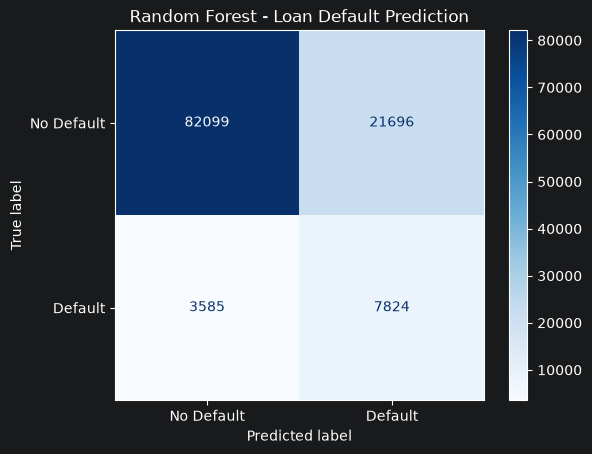

In [99]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions using the trained Random Forest
y_pred_rf = rf_model.predict(X_test_processed)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Display the confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Loan Default Prediction")
plt.show()

In [100]:
import sys
from importlib.metadata import version

print("Python", sys.version.split()[0])
for package in ["scikit-learn", "numpy", "scipy", "pandas", "joblib"]:
    print(package, version(package))

Python 3.14.7
scikit-learn 1.9.1
numpy 2.5.4
scipy 1.18.1
pandas 3.1.1
joblib 1.6.0
